In [12]:
import os
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import networkx as nx
import ipywidgets as widgets
from ipywidgets import interact

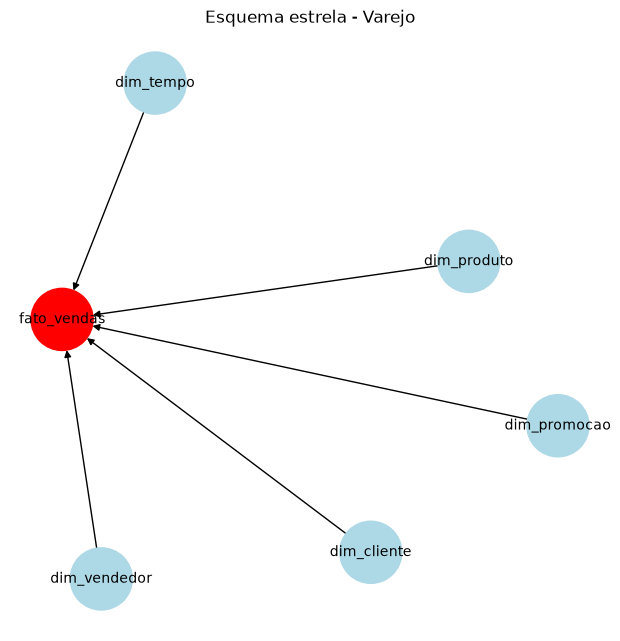

In [13]:
G = nx.DiGraph()
G.add_node("fato_vendas", color="red")

dimencoes = ["dim_produto", "dim_tempo", "dim_cliente", "dim_vendedor", "dim_promocao"]
for d in dimencoes:
    G.add_node(d, color="lightblue")
    G.add_edge(d, "fato_vendas")

color = [G.nodes[n]['color'] for n in G.nodes]
plt.figure(figsize=(6,6))
nx.draw(G, with_labels=True, node_color=color, node_size=2000, arrows=True, font_size=10)
plt.title("Esquema estrela - Varejo")
plt.show()

In [14]:
diretorio_dw = './datawarehouse'
caminho_banco = os.path.join(diretorio_dw, 'datawarehouse.db')

# Cria a pasta ./datawarehouse se não existir
os.makedirs(diretorio_dw, exist_ok=True)

# Remove o banco de dados anterior se ele já existir (garante substituição total)
if os.path.exists(caminho_banco):
    os.remove(caminho_banco)

In [15]:
df_clientes = pd.read_csv('./datalake/clean_data/clientes.csv')
df_vendedores = pd.read_csv('./datalake/clean_data/vendedores.csv')
df_estoque = pd.read_csv('./datalake/clean_data/estoque.csv')
df_promocoes = pd.read_csv('./datalake/clean_data/promocoes.csv')
df_vendas = pd.read_csv('./datalake/clean_data/vendas.csv')
df_crediario = pd.read_csv('./datalake/clean_data/crediario.csv')

In [16]:
# Dimensão Cliente
dim_cliente = df_clientes[['id_cliente', 'cidade', 'idade', 'canal_preferencial', 'data_cadastro']].copy()

# Dimensão Vendedor
dim_vendedor = df_vendedores[['id_vendedor', 'nome', 'cidade_loja', 'meta_mensal', 'data_contratacao']].copy()

# Dimensão Produto (extraído do cadastro/estoque)
dim_produto = df_estoque[[
    'id_produto', 'produto', 'categoria', 'cor', 'tamanho', 
    'preco_unitario', 'estoque_atual', 'estoque_minimo', 'estoque_maximo'
]].drop_duplicates()

# Dimensão Promoção
dim_promocao = df_promocoes[[
    'id_promocao', 'produto', 'categoria', 'desconto', 
    'tipo_desconto', 'data_inicio', 'data_fim'
]].copy()

# Dimensão Tempo
todas_as_datas = pd.concat([
    pd.to_datetime(df_vendas['data_venda'], errors='coerce'),
    pd.to_datetime(df_clientes['data_cadastro'], errors='coerce'),
    pd.to_datetime(df_vendedores['data_contratacao'], errors='coerce'),
    pd.to_datetime(df_crediario['data_vencimento'], errors='coerce'),
    pd.to_datetime(df_crediario['data_pagamento'], errors='coerce')
]).dropna().unique()

dim_tempo = pd.DataFrame({'data_dt': pd.to_datetime(todas_as_datas)}).sort_values('data_dt').reset_index(drop=True)
dim_tempo['id_tempo'] = dim_tempo['data_dt'].dt.strftime('%Y%m%d').astype(int)
dim_tempo['data'] = dim_tempo['data_dt'].dt.strftime('%Y-%m-%d')
dim_tempo['ano'] = dim_tempo['data_dt'].dt.year
dim_tempo['mes'] = dim_tempo['data_dt'].dt.month
dim_tempo['nome_mes'] = dim_tempo['data_dt'].dt.strftime('%B')
dim_tempo['dia'] = dim_tempo['data_dt'].dt.day
dim_tempo['dia_semana'] = dim_tempo['data_dt'].dt.strftime('%A')
dim_tempo['trimestre'] = dim_tempo['data_dt'].dt.quarter
dim_tempo = dim_tempo.drop(columns=['data_dt'])

In [17]:
# Fato Vendas
fato_vendas = df_vendas.copy()
fato_vendas['id_tempo'] = pd.to_datetime(fato_vendas['data_venda']).dt.strftime('%Y%m%d').astype('Int64')

colunas_fato_vendas = [
    'id_venda', 'id_cliente', 'id_vendedor', 'id_produto', 'id_tempo',
    'quantidade', 'preco_unitario', 'desconto', 'valor_total', 
    'canal', 'forma_pagamento', 'hora_venda'
]
fato_vendas = fato_vendas[colunas_fato_vendas]

In [18]:
conn = sqlite3.connect(caminho_banco)

dim_cliente.to_sql('dim_cliente', conn, if_exists='replace', index=False)
dim_vendedor.to_sql('dim_vendedor', conn, if_exists='replace', index=False)
dim_produto.to_sql('dim_produto', conn, if_exists='replace', index=False)
dim_promocao.to_sql('dim_promocao', conn, if_exists='replace', index=False)
dim_tempo.to_sql('dim_tempo', conn, if_exists='replace', index=False)
fato_vendas.to_sql('fato_vendas', conn, if_exists='replace', index=False)

print(f"Data Warehouse criado/substituído com sucesso em: {caminho_banco}")

Data Warehouse criado/substituído com sucesso em: ./datawarehouse/datawarehouse.db


In [19]:
query_analitica = """
SELECT 
    t.ano,
    t.nome_mes,
    p.categoria,
    v.nome AS vendedor,
    c.cidade AS cidade_cliente,
    SUM(f.quantidade) AS total_itens_vendidos,
    SUM(f.valor_total) AS faturamento_total
FROM fato_vendas f
JOIN dim_tempo t ON f.id_tempo = t.id_tempo
JOIN dim_produto p ON f.id_produto = p.id_produto
JOIN dim_vendedor v ON f.id_vendedor = v.id_vendedor
LEFT JOIN dim_cliente c ON f.id_cliente = c.id_cliente
GROUP BY t.ano, t.mes, p.categoria
ORDER BY t.ano DESC, t.mes DESC, faturamento_total DESC
LIMIT 10;
"""

resultado = pd.read_sql_query(query_analitica, conn)
print("\n--- Exemplo de Consulta Analítica no Star Schema ---")
print(resultado)


--- Exemplo de Consulta Analítica no Star Schema ---
    ano  nome_mes  categoria               vendedor         cidade_cliente  \
0  2026  November      Calça  Pedro Henrique Aragão                  Itobi   
1  2026  November   Camiseta       Ana Sophia Pires            Casa Branca   
2  2026  November    Vestido        Valentim da Paz  São João da Boa Vista   
3  2026  November  Acessório        Valentim da Paz                 Tambaú   
4  2026  November      Blusa          Antony Garcia                  Itobi   
5  2026  November    Jaqueta          Benício Souza  São José do Rio Pardo   
6  2026  November    Bermuda       Ana Sophia Pires                 Mococa   
7  2026   October      Calça        Valentim da Paz                 Mococa   
8  2026   October    Vestido  Pedro Henrique Aragão                  Aguaí   
9  2026   October   Camiseta          Sofia Fonseca  São José do Rio Pardo   

   total_itens_vendidos  faturamento_total  
0                   175           40924.89

In [20]:
# Consulta para estruturação do cubo tridimensional de vendas
query_cubo = """
    SELECT 
        c.idade AS Idade,
        f.quantidade AS Quantidade,
        f.valor_total AS Valor_Total,
        p.categoria AS Categoria,
        f.desconto AS Desconto
    FROM fato_vendas f
    JOIN dim_cliente c ON f.id_cliente = c.id_cliente
    JOIN dim_produto p ON f.id_produto = p.id_produto
"""

df_cubo = pd.read_sql_query(query_cubo, conn)

# Renderização do cubo OLAP em 3D
fig = px.scatter_3d(
    df_cubo,
    x='Idade',
    y='Quantidade',
    z='Valor_Total',
    color='Categoria',
    size='Desconto',
    title="Cubo OLAP: Idade do Cliente x Quantidade x Valor Total de Vendas"
)

fig.show()

In [21]:
# Dicionário de mapeamento de dimensões para a consulta OLAP
olap_dimensoes = {
    'Faixa Etária Cliente': """
        CASE
            WHEN c.idade < 30 THEN 'Menor de 30'
            WHEN c.idade BETWEEN 30 AND 50 THEN '30-50'
            ELSE 'Maior de 50'
        END
    """,
    'Categoria Produto': 'p.categoria',
    'Cidade da Loja': 'v.cidade_loja',
    'Canal de Venda': 'f.canal',
    'Forma de Pagamento': 'f.forma_pagamento',
    'Ano da Venda': 't.ano',
    'Mês da Venda': 't.nome_mes'
}

# Seletor da primeira dimensão
dim1_dropdown = widgets.Dropdown(
    options=list(olap_dimensoes.keys()),
    description='Dimensão 1:'
)

# Seletor da segunda dimensão ("Nenhuma" permite análise unidimensional)
dim2_dropdown = widgets.Dropdown(
    options=['Nenhuma'] + list(olap_dimensoes.keys()),
    description='Dimensão 2:'
)

# Função responsável por montar e executar a consulta OLAP
def gerar_consulta(dim1, dim2):
    # Recupera a expressão SQL correspondente à primeira dimensão
    col1 = olap_dimensoes[dim1]

    # Recupera a segunda dimensão, caso selecionada
    col2 = olap_dimensoes[dim2] if dim2 != 'Nenhuma' else None

    # Define a primeira coluna selecionada e a cláusula GROUP BY
    select_clause = f"{col1} AS dim1"
    group_clause = "dim1"

    # Adiciona a segunda dimensão se selecionada
    if col2:
        select_clause += f", {col2} AS dim2"
        group_clause += ", dim2"

    # Monta dinamicamente a consulta SQL agregando o total de vendas
    query = f"""
        SELECT
            {select_clause},
            SUM(f.valor_total) AS total_vendas,
            AVG(f.valor_total) AS media_vendas,
            SUM(f.quantidade) AS total_quantidade
        FROM fato_vendas f
        LEFT JOIN dim_cliente c ON f.id_cliente = c.id_cliente
        LEFT JOIN dim_vendedor v ON f.id_vendedor = v.id_vendedor
        LEFT JOIN dim_produto p ON f.id_produto = p.id_produto
        LEFT JOIN dim_tempo t ON f.id_tempo = t.id_tempo
        GROUP BY {group_clause}
        ORDER BY total_vendas DESC
    """

    # Executa a consulta SQL e carrega o resultado no DataFrame
    df_resultado = pd.read_sql_query(query, conn)

    # Configura a figura do gráfico
    plt.figure(figsize=(10, 5))

    # Gráfico bidimensional se houver duas dimensões
    if col2:
        sns.barplot(
            data=df_resultado,
            x='dim1',
            y='total_vendas',
            hue='dim2'
        )

        plt.legend(
            title=dim2,
            bbox_to_anchor=(1.05, 1),
            loc='upper left'
        )
    # Gráfico simples para apenas uma dimensão
    else:
        sns.barplot(
            data=df_resultado,
            x='dim1',
            y='total_vendas'
        )

    plt.title(
        f'Total de Vendas por {dim1}'
        + (f' e {dim2}' if col2 else '')
    )
    plt.xlabel(dim1)
    plt.ylabel('Total de Vendas (R$)')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Inicializa a interface interativa
interact(
    gerar_consulta,
    dim1=dim1_dropdown,
    dim2=dim2_dropdown
)

interactive(children=(Dropdown(description='Dimensão 1:', options=('Faixa Etária Cliente', 'Categoria Produto'…

<function __main__.gerar_consulta(dim1, dim2)>

In [22]:
#conn.close()